# PSTAT 197A Module 0 Report

**Sid Revanuru**\
**Clark Enge**\
**Hannah Damm**\
**Joyce Shu**\
**Ryan Au**

## Executive Summary
[to be filled out]
## Data Description

This data was obtained using a self-reported survey from all the students in the PSTAT 197A course. 55 students filled out the survey, 51 students filled out the background section of the data and 49 students filled out both the interest and background sections. The main characteristics obtained for each student were:
- Proficiency in math/stats/programming
- Upper division courses taken related to topic
- Whether the student specialized in a certain domain + list of specialized domains
- Project preference (Industry/Research)
- Preferred Programming language
- Areas of interest

Due to the fact that this was self-reported information, there could be some bias introduced in the data.

## Questions of Interest
The overall objective of this report is to investigate how students academic backgrounds and prior coursework relate to their technical confidence, programming preferences, and overall data science interests as they begin the PSTAT 197A. Specifically, our analysis addresses the following questions:

- Do the academic traits of students have an effect on their proficiency in math/stats/programming?
- Is coursework associated with self-rated comfort?
[more questions anyone else dove into]

## Findings

### 1. How much does coursework vary across the class?

> **[HANNAH: your figure + table + 3-4 sentences go here]**
> Figure: `../../figures/fig-coursework.png` · Table: `../../figures/tbl-upper-div.csv`


Looking at the survey data, almost every student took the same core classes, so there are only a few electives present that are differentiators between students. For example, PSTAT 100, 160, 134, 174, and CS 16 are different enough between students to tell them apart.

---

### 2. Is coursework associated with comfort?

We also tested whether the amount of coursework a student has completed is associated with how comfortable they feel in programming, math, and statistics. We used all 51 background respondents and two measures of coursework: the self-reported number of upper-division courses (3-5, 6-8, or 9+), and the number of electives taken. We counted electives as upper-division courses selected in the survey, leaving out required courses (PSTAT 120, 122, 126). Although most of the class has taken PSTAT 131, we opted to include it as an elective. We then calculated a Spearman correlation between each coursework measure and each comfort score, which gives 6 pairs in total. None of the 6 pairs showed an association: the correlations ranged from -0.15 to 0.16 and every p-value was above 0.25. The plot of comfort against number of electives shows the same thing, with students at every elective count spread across the full range of comfort levels. To check that this null result isn't just because of comfort is a noisy measure, we compared comfort to self-rated proficiency. The two line up closely: 94-97% of students who rated themselves advanced also gave a comfort of 4 or 5, compared with 44-60% of intermediate students. This suggests that comfort is a meaningful measure, but that coursework is not associated with it in this class, likely because coursework varies little across students and comfort comes from experience not included in the data.

![Comfort by number of electives](../fig-comfort.png)

*Figure 2. Comfort (2-5) by number of electives taken, for programming, math, and statistics.*

---

### 3a. Can coursework and interests predict comfort?

One of the tests that were ran was to test whether students academic characteristics could predict their self-assessed proficiency in concepts such as math, stats, and programming. We tested two distinct feature sets. The initial model was constrained by the curse of dimensionality, resulting in poor predictive power with balanced cross-validation scores of .54/.46/.40 across the three domains, performing near or below a coin flip. In the second iteration, a slightly more optimized feature set produced only a modest improvement, with balanced cross-validation scores shifting to .47/.57/.59. Because neither model significantly outperformed chance, these findings suggest both sample size limitations and that students academic background may simply not be a strong predictor of their perceived technical skills.

---

### 3b. Do students fall into distinct groups?

> 1. **What we did:** grouped the 49 students (the ones who answered both survey sections) with k-means,
>    trying 2 to 8 groups. To see if the groups were real, we compared against 200 "fake" versions
>    of the data where each column was shuffled randomly.
> 2. **What we found:** for 3+ groups, the real data had slightly clearer groups than the shuffled data,
>    but the groups were still very weak and overlap a lot (silhouette about 0.06; anything below about 0.25 is weak).
> 3. **What the groups are about:** mostly interests and background, not coursework. Group A (12 students)
>    liked biology/neuroscience/public health and image/text analysis. Group C (10 students) preferred R
>    and mostly had no research experience. Group B (27 students) is everyone else.
> 4. **Tie it to our main question:** Group C took the *most* coursework but had the *lowest* programming
>    comfort, so more coursework did not go with more comfort. This matches the Spearman result above.
> 5. **One honest caveat:** comfort scores were one of the inputs to the grouping, so some of the comfort
>    differences between groups come from that.

**What a silhouette score is:** for each student, it checks whether they are closer to their own group than they are to the next-closest group. It goes from -1 to +1. Near +1 means we have clean and seperate groups. Near 0 means the groups blur together. Ours is around 0.06 so the groups have a definite blur.

**Why we shuffled the data:** shuffling each column on its own keeps everyone's answer but it breaks the connection between them. Any "groups" that the k-means finds in the shufffled data are 
pure luck. If the real data beats the shuffled variations about 95% of the time, then the groups are not just luck.

**Why 3 groups**: 3 is the smallest number of groups that beat the shuffled data. It also held up when we used only the background questions or only the interest questions.

**How to read Figure 3:** each box shows the scores from the 200 shuffled datasets. The red dot is the real data. A dot above its box means the real data beat luck. At k=2 the dot sits inside the box, so 2 groups were no better than random chance.

**How to read Figure 4:** PCA squashes about 50 survey variables into 2 axes so that we can plot them. It only keeps aobut 18% of the total information, so some of the overlap comes from that squashing. Even so, the groups seem to sit in different areas with A on the upper right (biology/health interests), B spread through the middle, and C on the left(R users, no research).

**Coursework columm in the table:** 2.42, 2.56, and 2.90 all fall between the 6-8 classes and 9+ coursework selections. The groups barely differ in coursework, and the group with the most coursework (C) has the lowest programming comfort.


![Real data vs. shuffled data](../../figures/fig-cluster-null.png)

*Figure 3. How clearly k-means separates students into groups (silhouette score) for 2 to 8 groups. Boxes show 200 shuffled versions of the data, and red dots show the real data. Red dots above the boxes mean slightly more group structure than random chance.*

![Students coloured by group](../../figures/fig-cluster-pca.png)

*Figure 4. Each student plotted on the first two principal components and coloured by their k-means group (k = 3). The groups lean toward different areas but overlap heavily.*

*Table 1. Average comfort (2-5 scale) and coursework level (1 = 3-5 classes, 2 = 6-8, 3 = 9+) in each group.*

| Group | Students | Prog. comfort | Math comfort | Stat comfort | Coursework level (1-3) |
|---|---|---|---|---|---|
| A | 12 | 3.50 | 3.75 | 3.67 | 2.42 |
| B | 27 | 4.04 | 4.26 | 4.48 | 2.56 |
| C | 10 | 3.00 | 3.50 | 3.80 | 2.90 |

---

### Takeaway
From what we've seen  through the logistic regression, the Spearman correlations, and the clustering, we found that coursework barely varies across students. Coursework doesn't seem to be linked to comfort so its unlikely we could use it to predict comfort accurately. From the groups that do appear, they seem to be mostly dependent on interests, not coursework. This suggests that comfort comes from things that the survey did not ask about. For example, projects, internships, etc, that lend themselves to more experience and therefore comfort.


## Code Chunks
**Logistic Regression model #1**

For this model, I dummy-coded all the list columns (courses, areas), added language data, and how many upper-division courses the student took. This model suffers from the curse of dimensionality, with way too many features for just a 49-observation dataset. This resulted in the cross-validation scores being worse than a coin flip for the most part.

In [8]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
import os
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

background_data = pd.read_csv("../../data/background-clean.csv")
summary_data = pd.read_csv("../../data/class-summary.csv")
interest_data = pd.read_csv("../../data/interest-clean.csv")

background_data["separated_courses"] = background_data['courses'].str.split(", ")
interest_data['separated_areas'] = interest_data['areas'].str.split(', ')

merged_df = pd.merge(background_data, interest_data, on='response_id')
merged_df = merged_df.drop(columns=['separated_courses', 'separated_areas'])

feature_df = merged_df.drop(columns=['prog.prof', 'math.prof', 'stat.prof', 'response_id', 'domain_specialization', 'research', 'type'])
feature_df['9_or_more'] = np.where(feature_df['upper_div_courses'] == '9+', 1, 0)
feature_df = pd.get_dummies(feature_df, columns=['language'], drop_first=True)
dum_courses = feature_df['courses'].str.get_dummies(sep=", ")
dum_areas = feature_df['areas'].str.get_dummies(sep=", ")
feature_df = pd.concat([feature_df, dum_courses, dum_areas], axis=1)
feature_df = feature_df.drop(columns=['upper_div_courses', 'generally','domains','courses', 'areas', 'PSTAT 120', 'PSTAT 126', 'PSTAT 131', 'CS 9', 'LING 110', 'GEOG 186', 'LING 104', 'CS 130'])

target_values = ['prog.comf', 'math.comf', 'stat.comf']

X = feature_df.drop(target_values, axis=1)
y = (feature_df[target_values] >= 4).astype(int)

cross_validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=69)

models, results, coefs = {}, {}, {}
for t in target_values:
    y_t = y[t]
    model = LogisticRegression(C=0.5, class_weight='balanced', max_iter=1000)
    results[t] = {'n_comfortable': y_t.sum(),
        'n_not': (1 - y_t).sum(),
        'cv_accuracy': cross_val_score(model, X, y_t, cv=cross_validation, scoring='accuracy').mean(),
        'cv_balanced_acc': cross_val_score(model, X, y_t, cv=cross_validation, scoring='balanced_accuracy').mean(),}

    model.fit(X,y_t)
    models[t] = model
    coefs[t] = pd.Series(model.coef_[0], index=X.columns)
results_df = pd.DataFrame(results).T
coef_df = pd.DataFrame(coefs)
results_df

,n_comfortable,n_not,cv_accuracy,cv_balanced_acc
prog.comf,28.0,21.0,0.548889,0.541667
math.comf,37.0,12.0,0.551111,0.460714
stat.comf,40.0,9.0,0.591111,0.400000


**Logistic Regression model #2**

For this slightly refined model, I cut down on the features heavily from 24 to 9 and implemented StandardScaler in the pipeline. This feature set included a lot of total counts instead of including every course and area. Some of these features included:
- Number of cs/pstat classes
- Total courses taken
- Domain Specialization (Y/N)
- Research (Y/N)\
Using these features along with scaling them, resulted in a modest improvement, with the balanced cross-validation scores being a little better than a coin flip this time around. These scores are still not significant at all and this shows that the features given in this survey may not be a good predictor of the students self-assessed proficiency. The small sample size may also be a factor as well.

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

merged_df['n_pstat'] = merged_df['courses'].str.count(r'\bPSTAT ')
merged_df['n_cs']    = merged_df['courses'].str.count(r'\bCS ')
merged_df['total_courses'] = merged_df[['n_pstat', 'n_cs']].sum(axis=1)
merged_df['n_areas'] = merged_df['areas'].str.split(", ")
merged_df['n_areas'] = [[x for x in lst if x != 'generally'] for lst in merged_df['n_areas']]
merged_df['n_areas'] = [len(x) for x in merged_df['n_areas']]
merged_df['9_or_more'] = np.where(merged_df['upper_div_courses'] == '9+', 1, 0)
merged_df = merged_df.drop(['response_id','prog.prof', 'math.prof', 'stat.prof', 'upper_div_courses', 'courses', 'type', 'domains', 'areas'], axis=1)
merged_df = pd.get_dummies(merged_df, columns=['language'], drop_first=True, dtype=int)
merged_df['domain_specialization'] = (merged_df['domain_specialization'] == "Yes").astype(int)
merged_df['research'] = (merged_df['research'] == "Yes").astype(int)

target_values = ['prog.comf', 'math.comf', 'stat.comf']

X = merged_df.drop(target_values, axis=1)
y = (merged_df[target_values] >= 4).astype(int)

cross_validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=69)

models, results, coefs = {}, {}, {}
for t in target_values:
    y_t = y[t]
    model = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, class_weight='balanced', max_iter=1000))

    results[t] = {'n_comfortable': y_t.sum(),
        'n_not': (1 - y_t).sum(),
        'cv_accuracy': cross_val_score(model, X, y_t, cv=cross_validation, scoring='accuracy').mean(),
        'cv_balanced_acc': cross_val_score(model, X, y_t, cv=cross_validation, scoring='balanced_accuracy').mean(),}

    model.fit(X,y_t)
    models[t] = model
    coefs[t] = pd.Series(model[-1].coef_[0], index=X.columns)
results_df = pd.DataFrame(results).T
coef_df = pd.DataFrame(coefs)
results_df

,n_comfortable,n_not,cv_accuracy,cv_balanced_acc
prog.comf,28.0,21.0,0.468889,0.475000
math.comf,37.0,12.0,0.613333,0.575595
stat.comf,40.0,9.0,0.633333,0.587500


**Spearman Correlation**

For this analysis, I counted the number of electives each student has taken by keeping only upper-division courses and dropping the required core classes PSTAT 120, 122, and 126. Despite almost every student having taken 131, I included it as it is still considered an elective. I also turned the upper-division course question (3-5 / 6-8 / 9+) into a 1/2/3 scale. I used a Spearman correlation because comfort is ranked on a 2-5 scale rather than a true number, and Spearman only looks at whether the rankings move together. This gave 6 tests (2 coursework measures x 3 comfort scores), and none of them were significant. The second table cross-tabulates proficiency with comfort to show that the comfort question is still picking up something real, since students who rate themselves advanced almost always report high comfort.

,coursework,comfort,rho,p_value
0,coursework_level,Programming,0.047,0.742
1,coursework_level,Mathematics,0.026,0.855
2,coursework_level,Statistics,-0.148,0.300
3,n_electives,Programming,0.160,0.263
4,n_electives,Mathematics,-0.133,0.352
5,n_electives,Statistics,-0.069,0.629


,skill,2,3,4,5
adv,Programming,0,1,10,5
beg,Programming,0,3,0,0
int,Programming,1,17,11,3
adv,Mathematics,1,0,9,11
int,Mathematics,3,9,15,3
adv,Statistics,0,1,18,14
int,Statistics,0,8,8,2


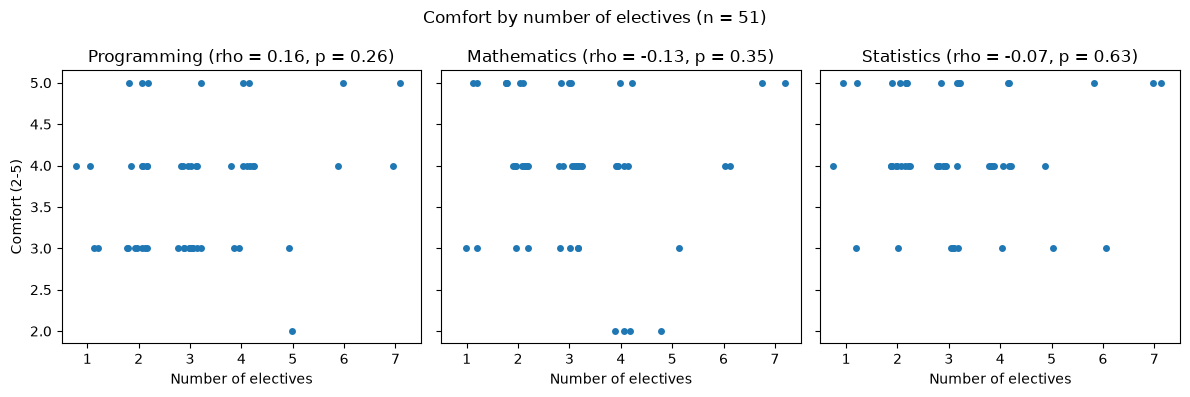

In [12]:
import re
from scipy.stats import spearmanr

comfort_df = pd.read_csv("../../data/background-clean.csv")

skills = {"prog": "Programming", "math": "Mathematics", "stat": "Statistics"}
core = {"PSTAT 120", "PSTAT 122", "PSTAT 126"}  # required core; PSTAT 131 is an elective

def count_electives(courses):
    labels = [c.strip() for c in courses.split(",")]
    return sum(int(re.search(r"\d+", c).group()) >= 100 and c not in core for c in labels)

comfort_df["n_electives"] = comfort_df["courses"].map(count_electives)
comfort_df["coursework_level"] = comfort_df["upper_div_courses"].map({"3-5": 1, "6-8": 2, "9+": 3})

# Spearman correlations: 2 coursework measures x 3 comfort scores
rows = []
for pred in ["coursework_level", "n_electives"]:
    for skill, label in skills.items():
        res = spearmanr(comfort_df[pred], comfort_df[f"{skill}.comf"])
        rows.append({"coursework": pred, "comfort": label,
                    "rho": round(res.statistic, 3), "p_value": round(res.pvalue, 3)})
spearman_df = pd.DataFrame(rows)
display(spearman_df)

# Proficiency vs comfort: shows the comfort measure is coherent
tabs = []
for skill, label in skills.items():
    tab = pd.crosstab(comfort_df[f"{skill}.prof"], comfort_df[f"{skill}.comf"].astype(int))
    tab = tab.reindex(columns=[2, 3, 4, 5], fill_value=0)
    tab.insert(0, "skill", label)
    tabs.append(tab)
display(pd.concat(tabs))

# Figure: comfort by number of electives
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, (skill, label) in zip(axes, skills.items()):
    sns.stripplot(data=comfort_df, x="n_electives", y=f"{skill}.comf", jitter=0.25, ax=ax)
    r = spearman_df.query("coursework == 'n_electives' and comfort == @label").iloc[0]
    ax.set_title(f"{label} (rho = {r.rho:.2f}, p = {r.p_value:.2f})")
    ax.set_xlabel("Number of electives")
    ax.set_ylabel("Comfort (2-5)")
fig.suptitle(f"Comfort by number of electives (n = {len(comfort_df)})")
fig.tight_layout()
plt.show()

## Plots/Figures

**Heatmap of correleted classes and areas of intrest**

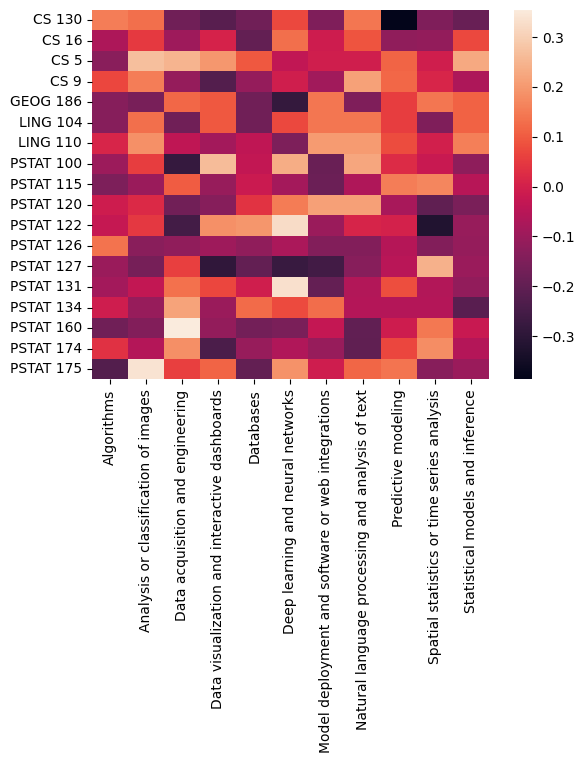

**Most popular subject areas**

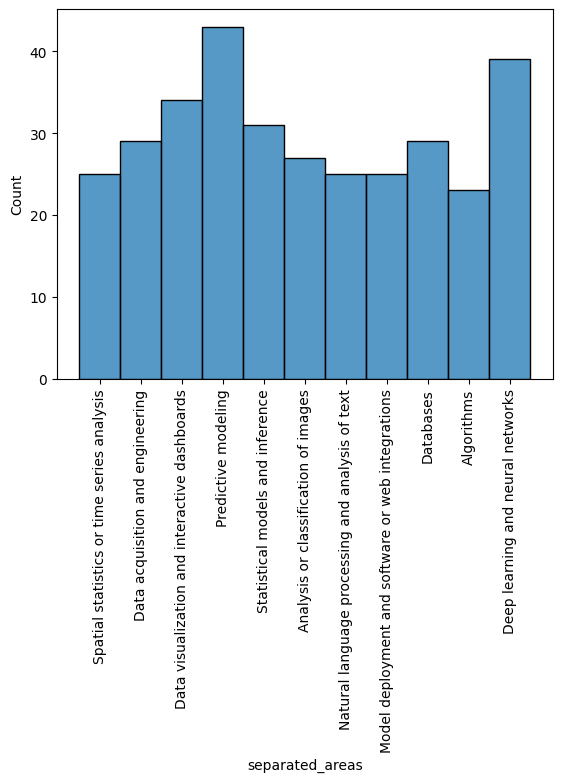

**Most popular courses**

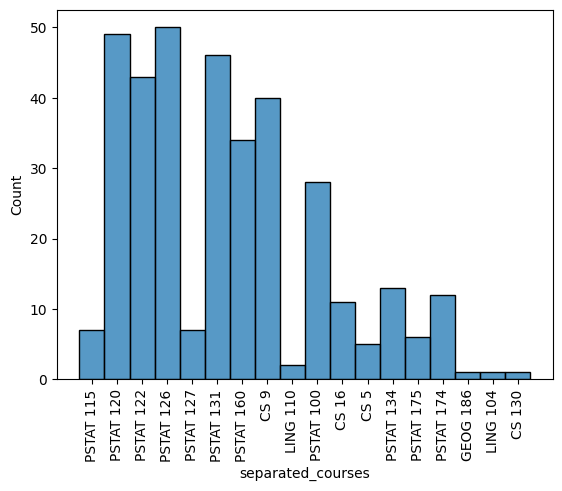

**Comfort by number of electives**
![Comfort by number of electives](../fig-comfort.png)